In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from helpers.log_helper import open_log
import pandas as pd

In [4]:
df = open_log("/Users/gustavoschwarz/TunerStudioProjects/MeuCarro 2/DataLogs/2026-09-16_14.09.31.msl")

In [5]:
#df_filtered = df[238:513]

In [6]:
#df_filtered.to_csv("golquadrado/data/pegou_morreu_filtered.csv", index=False)  # Save the filtered dataframe to a new file

In [7]:
#df_filtered = df[(df['Time'] >= 460) & (df["Time"] <= 500)]

df_filtered = df[(df['Time'] >= 10)]

In [8]:
df.columns

Index(['Time', 'SecL', 'RPM', 'MAP', 'MAPxRPM', 'TPS', 'AFR', 'Lambda', 'IAT',
       'CLT', 'Engine', 'DFCO', 'Gego', 'Gair', 'Gbattery', 'Gwarm', 'Gbaro',
       'Gammae', 'Accel Enrich', 'VE (Current', 'VE1', 'VE2', 'PW', 'PW2',
       'PW3', 'PW4', 'AFR Target', 'Lambda Target', 'Duty Cycle',
       'Duty Cycle (Staging', 'TPS DOT', 'Advance (Current', 'Dwell',
       'Dwell (Measured', 'Battery V', 'rpm/s', 'Error #', 'Error ID',
       'Boost PSI', 'Boost cut', 'Hard Launch', 'Hard Limiter', 'Idle Control',
       'IAC value', 'Idle Target RPM', 'Idle RPM Delta', 'Baro Pressure',
       'Fan', 'Sync Loss #', 'Loops/s', 'Loops/rev', 'Aux0', 'Aux1', 'Aux2',
       'Aux3', 'Aux4', 'Aux5', 'Aux6', 'Aux7', 'Aux8', 'Aux9', 'Aux10',
       'Aux11', 'Aux12', 'Aux13', 'Aux14', 'Aux15', 'Advance 1', 'Advance 2',
       'FuelLoad', 'IgnitionLoad', 'Sync status', 'Engine Prot. RPM',
       'Engine Prot. CLT', 'Trip Meter Miles', 'Odometer Miles',
       'Vehicle Speed', 'Power', 'Torque'],
 

In [9]:
df_filtered

,Time,SecL,RPM,MAP,MAPxRPM,TPS,AFR,Lambda,IAT,CLT,...,FuelLoad,IgnitionLoad,Sync status,Engine Prot. RPM,Engine Prot. CLT,Trip Meter Miles,Odometer Miles,Vehicle Speed,Power,Torque
153,10.063,39.0,0.0,99.0,0.0,0.0,5.0,0.556,25.0,17.0,...,99.0,99.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
154,10.130,39.0,0.0,98.0,0.0,0.0,5.0,0.556,25.0,17.0,...,98.0,98.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
155,10.197,39.0,0.0,98.0,0.0,0.0,5.0,0.556,25.0,17.0,...,98.0,98.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
156,10.259,39.0,0.0,98.0,0.0,0.0,5.0,0.556,25.0,17.0,...,98.0,98.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
157,10.328,39.0,0.0,98.0,0.0,0.0,5.0,0.556,25.0,17.0,...,98.0,98.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29949,1999.295,156.0,1227.0,42.0,51534.0,0.0,9.4,1.044,41.0,85.0,...,42.0,42.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
29950,1999.361,156.0,1224.0,39.0,47736.0,0.0,9.3,1.033,41.0,85.0,...,39.0,39.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
29951,1999.426,156.0,1216.0,40.0,48640.0,0.0,9.3,1.033,41.0,85.0,...,40.0,40.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
29952,1999.497,156.0,1218.0,41.0,49938.0,0.0,9.3,1.033,41.0,85.0,...,41.0,41.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0


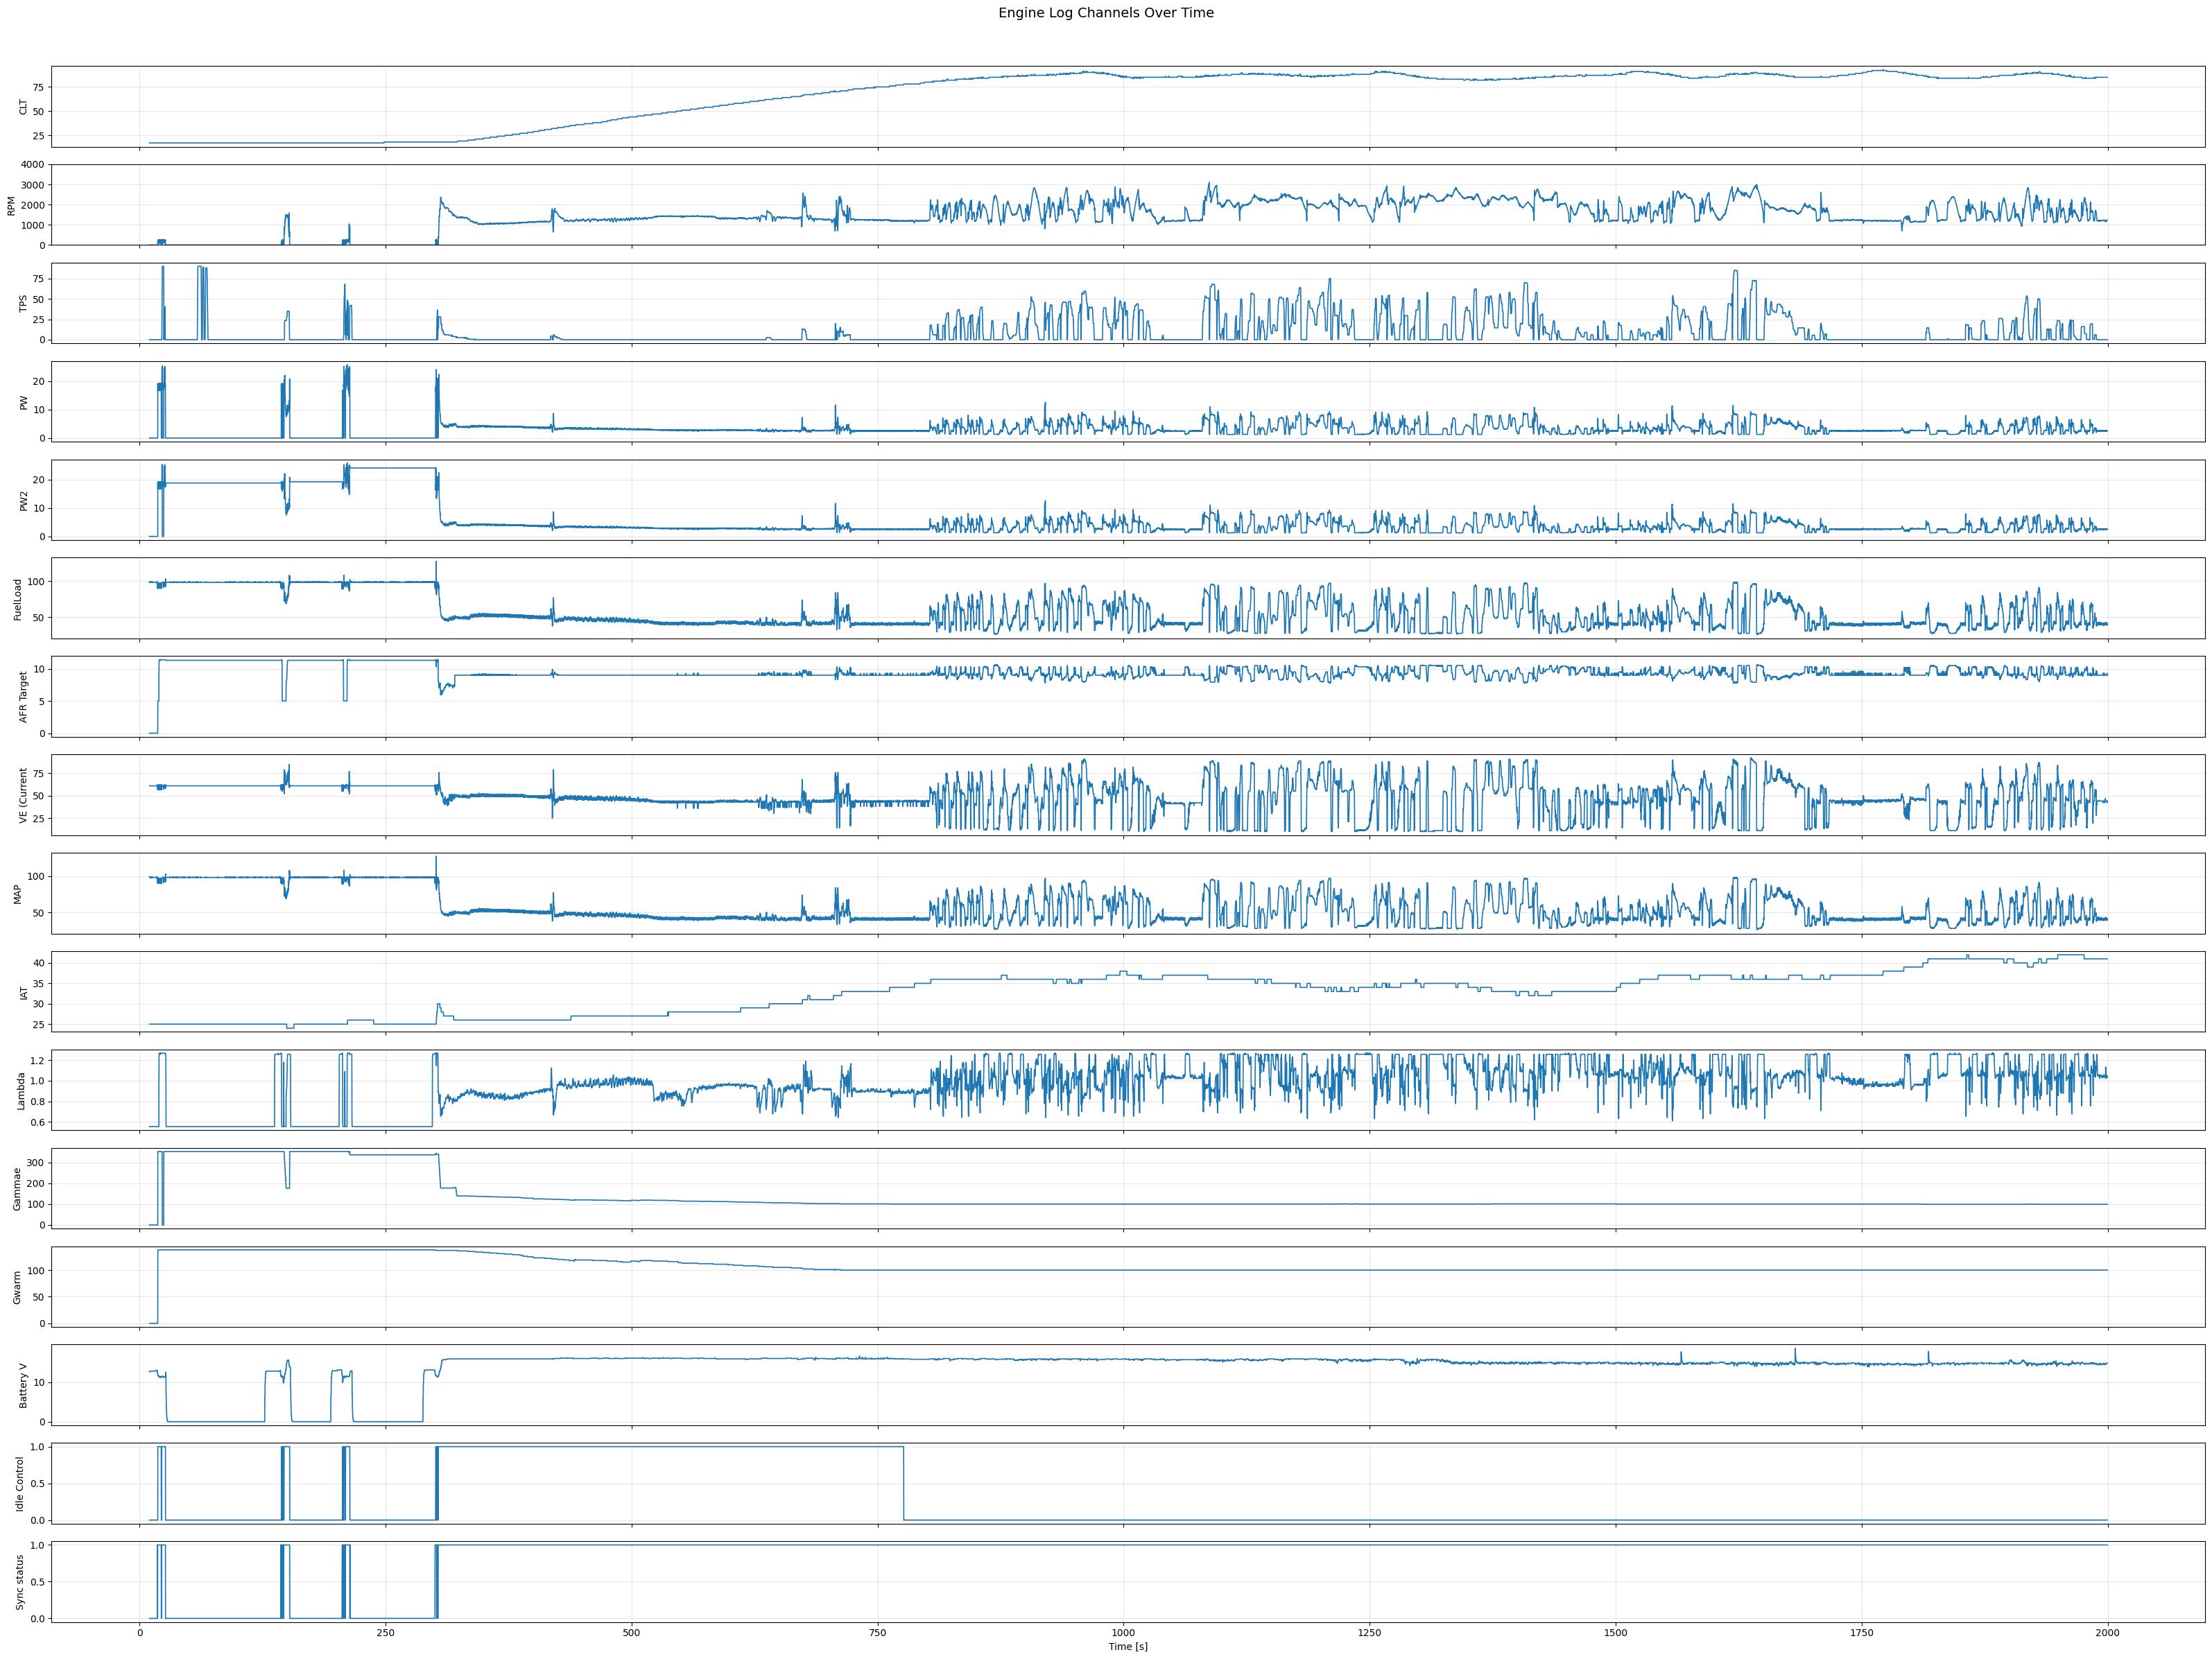

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SHOW = False                       # True to pop up each figure

# Downsample/smooth options for huge logs (set both to None to disable)
DOWNSAMPLE_STEP = None    # e.g., 5  -> take every 5th row
ROLLING_WINDOW = None     # e.g., 5  -> rolling mean over 5 samples

# === LOAD ===
df = df_filtered

# Normalize time
t = pd.to_numeric(df["Time"], errors="coerce")
#t = t - t.iloc[0]

# Define variables to plot (in order)
channels = [
    "CLT",
    "RPM",
    "TPS",
    "PW",
    "PW2",
    "FuelLoad",
    "AFR Target",
    "VE (Current",
    "MAP",
    "IAT",
    "Lambda",
    "Gammae",
    "Gwarm",
    "Battery V",
    "Idle Control",
    "Sync status"
]

# Filter only available ones
available = [c for c in channels if c in df.columns]
missing = [c for c in channels if c not in df.columns]
if missing:
    print("⚠️ Missing:", missing)

# === Plot all in one figure ===
n = len(available)
fig, axes = plt.subplots(n, 1, figsize=(32, 1.5 * n), sharex=True)
if n == 1:
    axes = [axes]  # ensure iterable if only one

for ax, col in zip(axes, available):
    ax.plot(t, df[col], linewidth=1.2)
    ax.set_ylabel(col)
    
    if col in ["RPM"]:
        ax.set_ylim(0, 4000)
    ax.grid(True, alpha=0.3)
    #ax.set_xlim(t.min(), t.max())



axes[-1].set_xlabel("Time [s]")
fig.suptitle("Engine Log Channels Over Time", fontsize=14, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

In [22]:
df_filtered

,Time,SecL,RPM,MAP,MAPxRPM,TPS,AFR,Lambda,IAT,CLT,...,FuelLoad,IgnitionLoad,Sync status,Engine Prot. RPM,Engine Prot. CLT,Trip Meter Miles,Odometer Miles,Vehicle Speed,Power,Torque
6855,460.016,124.0,1240.0,43.0,53320.0,0.0,7.9,0.878,35.0,66.0,...,43.0,43.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
6856,460.081,124.0,1246.0,41.0,51086.0,0.0,7.9,0.878,35.0,66.0,...,41.0,41.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
6857,460.148,124.0,1249.0,42.0,52458.0,0.0,7.9,0.878,35.0,66.0,...,42.0,42.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
6858,460.214,124.0,1248.0,43.0,53664.0,0.0,7.9,0.878,35.0,66.0,...,43.0,43.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
6859,460.282,124.0,1254.0,44.0,55176.0,0.0,7.9,0.878,35.0,66.0,...,44.0,44.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7072,474.485,138.0,1767.0,49.0,86583.0,6.0,8.8,0.978,36.0,67.0,...,49.0,49.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
7073,474.549,138.0,1822.0,47.0,85634.0,6.0,8.5,0.944,36.0,67.0,...,47.0,47.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
7074,474.615,138.0,1863.0,46.0,85698.0,6.0,8.3,0.922,36.0,67.0,...,46.0,46.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
7075,474.682,138.0,1900.0,46.0,87400.0,6.0,8.1,0.900,36.0,67.0,...,46.0,46.0,1.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0
